[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/02_instancenorm_trap_and_ltn_math.ipynb)

# Companion Notebook 02 — The `InstanceNorm3d` Coordinate-Erasure Trap & LTN Real-Logic Mathematics

*Companion to the BMED365 Technical Report (`../neurosymbolic-kiwi-report.pdf`)*  
*Reproduces: **Section 2.3–2.4**, **Section 3.2**, **Figures 3 & 4**, **Table 2**, and **Appendices B & D** (`../results/nb02_instancenorm_and_ltn.json`)*

### Purpose
1. Prove experimentally on real equatorial (`z = 56..71`), mid-latitude (`z = 32..47`), and polar (`z = 0..15`) crops that patch-wise `nn.InstanceNorm3d` completely erases absolute organ location — motivating our **Bayes Log-Odds `Organ-GPS`** architecture (`+353` parameters).
2. Compare three classical fuzzy implication families (**Product / Reichenbach**, **Łukasiewicz**, **Gödel**) on gradient smoothness and dead zones.
3. Compute the exact loss and gradient amplification of LTN's generalized $p$-mean universal quantifier across $p \in [1, 8]$ on a simulated `40,960`-voxel polar cube containing `0.8%` (`328` voxels) vascular false positives.

In [1]:
import json
import sys
import urllib.request
from pathlib import Path

# Auto-fetch shared library `kiwi_ns_lib.py` if opened standalone in Google Colab
if not Path("kiwi_ns_lib.py").exists():
    for cand in [Path("docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
                 Path("Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py")]:
        if cand.exists():
            sys.path.insert(0, str(cand.parent.resolve()))
            break
    else:
        url = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"
        print("Downloading kiwi_ns_lib.py from GitHub main for Colab session...")
        urllib.request.urlretrieve(url, "kiwi_ns_lib.py")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import importlib.util
for pkg in ("nibabel", "torch"):
    if importlib.util.find_spec(pkg) is None:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage as ndi
from scipy.spatial.distance import cdist
from skimage import measure

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "font.size": 9.5})

import kiwi_ns_lib as kns

DEVICE = kns.get_best_device()
FIG_DIR, RES_DIR = kns.resolve_report_dirs()
print(f"Device: {DEVICE} | Figures -> {FIG_DIR} | Results -> {RES_DIR}")

Device: mps | Figures -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/figures | Results -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results


## 1. Direct Proof of `InstanceNorm3d` Coordinate Erasure Across Three Anatomical Latitudes

RAW pole means         -> Equator=0.063 | Mid-Lat=0.378 | Pole=0.882
AFTER InstanceNorm3d   -> Equator=-0.000000 | Mid-Lat=0.000000 | Pole=0.000000
Max pointwise diff between Mid-Latitude (z=32..47) and Polar Cap (z=0..15) AFTER InstanceNorm3d: 4.77e-07 (IDENTICAL!)
Params -> MultiTaskUNet3D: 340,450 | AdditiveBayesOrganNet3D: 340,803 (+353) | CoupledOrganNet3D: 341,314 (+864)


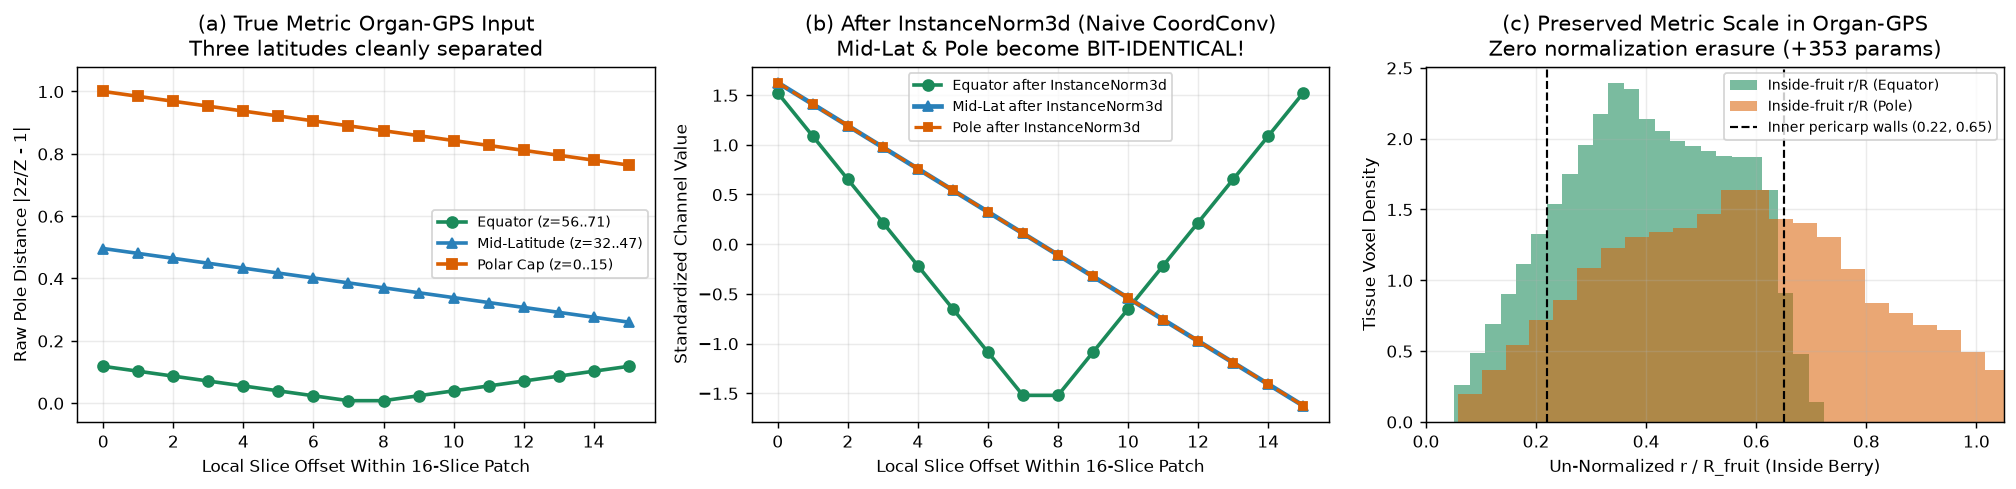

In [2]:
ds = kns.load_kiwi_dataset()

# Extract three 64x40x16 crops spanning Equator, Mid-Latitude, and Polar Cap
_, gps_eq  = kns.make_3ch_and_gps(ds, 128, 192, 128, 168, 56, 72)
_, gps_mid = kns.make_3ch_and_gps(ds, 112, 176, 112, 152, 32, 48)
_, gps_pol = kns.make_3ch_and_gps(ds, 96,  160, 96,  136, 0,  16)

inorm = torch.nn.InstanceNorm3d(3, affine=False)
g_eq_in, g_mid_in, g_pol_in = inorm(gps_eq), inorm(gps_mid), inorm(gps_pol)

z_eq_r, z_mid_r, z_pol_r = [g[0, 2, 32, 20, :].numpy() for g in (gps_eq, gps_mid, gps_pol)]
z_eq_i, z_mid_i, z_pol_i = [g[0, 2, 32, 20, :].numpy() for g in (g_eq_in, g_mid_in, g_pol_in)]

max_diff_mid_pol_after = float(np.max(np.abs(z_mid_i - z_pol_i)))
print(f"RAW pole means         -> Equator={z_eq_r.mean():.3f} | Mid-Lat={z_mid_r.mean():.3f} | Pole={z_pol_r.mean():.3f}")
print(f"AFTER InstanceNorm3d   -> Equator={z_eq_i.mean():.6f} | Mid-Lat={z_mid_i.mean():.6f} | Pole={z_pol_i.mean():.6f}")
print(f"Max pointwise diff between Mid-Latitude (z=32..47) and Polar Cap (z=0..15) AFTER InstanceNorm3d: {max_diff_mid_pol_after:.2e} (IDENTICAL!)")

# Parameter counts of all three model families
n_base = sum(p.numel() for p in kns.MultiTaskUNet3D(3).parameters())
n_add = sum(p.numel() for p in kns.AdditiveBayesOrganNet3D().parameters())
n_cpl = sum(p.numel() for p in kns.CoupledOrganNet3D().parameters())
print(f"Params -> MultiTaskUNet3D: {n_base:,} | AdditiveBayesOrganNet3D: {n_add:,} (+{n_add-n_base}) | CoupledOrganNet3D: {n_cpl:,} (+{n_cpl-n_base})")

# Figure 3: 3-Panel Coordinate-Erasure Proof
fig, axes = plt.subplots(1, 3, figsize=(15.6, 3.85))
s_idx = np.arange(16)

axes[0].plot(s_idx, z_eq_r,  "o-", color="#1b8a5a", lw=2.0, label="Equator (z=56..71)")
axes[0].plot(s_idx, z_mid_r, "^-", color="#2980b9", lw=2.0, label="Mid-Latitude (z=32..47)")
axes[0].plot(s_idx, z_pol_r, "s-", color="#d95f02", lw=2.0, label="Polar Cap (z=0..15)")
axes[0].set_ylim(-0.06, 1.08)
axes[0].set_xlabel("Local Slice Offset Within 16-Slice Patch")
axes[0].set_ylabel("Raw Pole Distance |2z/Z - 1|")
axes[0].set_title("(a) True Metric Organ-GPS Input\nThree latitudes cleanly separated")
axes[0].legend(fontsize=7.8)
axes[0].grid(alpha=0.25)

axes[1].plot(s_idx, z_eq_i,  "o-", color="#1b8a5a", lw=2.0, label="Equator after InstanceNorm3d")
axes[1].plot(s_idx, z_mid_i, "^-", color="#2980b9", lw=2.6, label="Mid-Lat after InstanceNorm3d")
axes[1].plot(s_idx, z_pol_i, "s--", color="#d95f02", lw=1.8, markersize=4.5, label="Pole after InstanceNorm3d")
axes[1].set_xlabel("Local Slice Offset Within 16-Slice Patch")
axes[1].set_ylabel("Standardized Channel Value")
axes[1].set_title("(b) After InstanceNorm3d (Naive CoordConv)\nMid-Lat & Pole become BIT-IDENTICAL!")
axes[1].legend(fontsize=7.6)
axes[1].grid(alpha=0.25)

m_eq = ds.fruit_mask[128:192, 128:168, 56:72]
m_pol = ds.fruit_mask[96:160, 96:136, 0:16]
axes[2].hist(gps_eq[0, 0].numpy()[m_eq], bins=24, alpha=0.58, color="#1b8a5a", density=True, label="Inside-fruit r/R (Equator)")
axes[2].hist(gps_pol[0, 0].numpy()[m_pol], bins=24, alpha=0.55, color="#d95f02", density=True, label="Inside-fruit r/R (Pole)")
axes[2].axvline(0.22, color="k", ls="--", lw=1.2, label="Inner pericarp walls (0.22, 0.65)")
axes[2].axvline(0.65, color="k", ls="--", lw=1.2)
axes[2].set_xlim(0.0, 1.05)
axes[2].set_xlabel("Un-Normalized r / R_fruit (Inside Berry)")
axes[2].set_ylabel("Tissue Voxel Density")
axes[2].set_title("(c) Preserved Metric Scale in Organ-GPS\nZero normalization erasure (+353 params)")
axes[2].legend(fontsize=7.5)
axes[2].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig03_instancenorm_coordinate_erasure.png", bbox_inches="tight")
plt.show()

## 2. Comparing Fuzzy Implication Families & LTN $p$-Mean Gradient Amplification

,p,loss,grad_fp,fp_bg_ratio,gain_vs_p1,pct_grad_on_fp
0,1.0,0.0175,0.0080,8.072455e-03,1.00,0.80
1,1.5,0.0413,0.0384,7.868055e-02,4.79,7.29
2,2.0,0.0856,0.0889,7.668831e-01,11.10,43.40
3,3.0,0.1901,0.2000,7.285391e+01,24.98,98.65
4,4.0,0.2842,0.2991,6.921120e+03,37.36,99.99
5,6.0,0.4249,0.4473,6.246313e+07,55.86,100.00
6,8.0,0.5196,0.5469,5.469387e+11,68.30,100.00


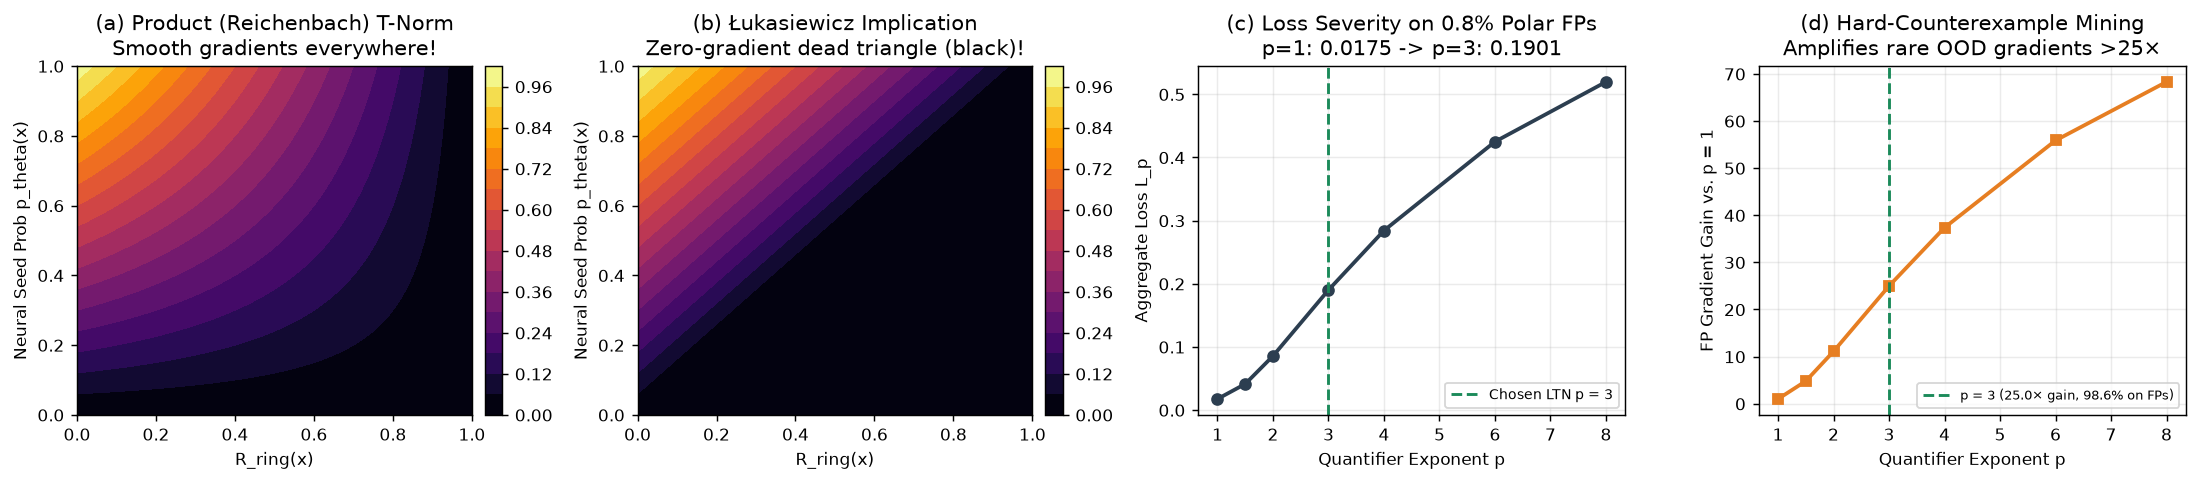

In [3]:
# Compare Product (Reichenbach), Łukasiewicz, and Gödel violation surfaces on premise = (1 - R_ring), conclusion = (1 - p_theta)
r_vals = np.linspace(0.0, 1.0, 120)
p_vals = np.linspace(0.0, 1.0, 120)
RR, PP = np.meshgrid(r_vals, p_vals)
prem_t = torch.from_numpy((1.0 - RR).astype(np.float32))
conc_t = torch.from_numpy((1.0 - PP).astype(np.float32))
V_prod = kns.implication_violation(prem_t, conc_t, "product").numpy()
V_luka = kns.implication_violation(prem_t, conc_t, "lukasiewicz").numpy()

# Quantifier power sweep on simulated 64 x 40 x 16 = 40,960-voxel polar cube with 0.8% (328 voxels) vascular FPs
n_vox = 64 * 40 * 16
n_fp = int(round(0.008 * n_vox))
p_grid = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0]
p_rows = []
g0 = None
for pv in p_grid:
    v = torch.full((n_vox,), 0.01, dtype=torch.float32)
    v[:n_fp] = 0.95
    v.requires_grad_(True)
    lv = kns.ltn_universal_pmean(v, p=pv)
    lv.backward()
    g_fp = float(v.grad[:n_fp].sum().item())
    g_bg = float(v.grad[n_fp:].sum().item())
    if g0 is None:
        g0 = g_fp
    p_rows.append({
        "p": pv,
        "loss": round(float(lv.item()), 4),
        "grad_fp": round(g_fp, 4),
        "fp_bg_ratio": g_fp / max(g_bg, 1e-12),
        "gain_vs_p1": round(g_fp / g0, 2),
        "pct_grad_on_fp": round(100.0 * g_fp / (g_fp + g_bg), 2),
    })

df_p = pd.DataFrame(p_rows)
display(df_p)

out_nb02 = {
    "raw_means": {"equator": round(float(z_eq_r.mean()), 4), "mid_lat": round(float(z_mid_r.mean()), 4), "pole": round(float(z_pol_r.mean()), 4)},
    "inorm_means": {"equator": round(float(z_eq_i.mean()), 6), "mid_lat": round(float(z_mid_i.mean()), 6), "pole": round(float(z_pol_i.mean()), 6)},
    "max_diff_mid_pol_after_inorm": max_diff_mid_pol_after,
    "param_counts": {"baseline": n_base, "additive_gps": n_add, "coupled_gps": n_cpl},
    "pmean_sweep": p_rows,
}
(RES_DIR / "nb02_instancenorm_and_ltn.json").write_text(json.dumps(out_nb02, indent=2), encoding="utf-8")

# Figure 4: 4-Panel Fuzzy Implications & LTN p-Mean Gradient Dynamics
fig, axes = plt.subplots(1, 4, figsize=(17.0, 3.8))

im0 = axes[0].contourf(RR, PP, V_prod, levels=16, cmap="inferno")
axes[0].set_xlabel("R_ring(x)")
axes[0].set_ylabel("Neural Seed Prob p_theta(x)")
axes[0].set_title("(a) Product (Reichenbach) T-Norm\nSmooth gradients everywhere!")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.03)

im1 = axes[1].contourf(RR, PP, V_luka, levels=16, cmap="inferno")
axes[1].set_xlabel("R_ring(x)")
axes[1].set_ylabel("Neural Seed Prob p_theta(x)")
axes[1].set_title("(b) Łukasiewicz Implication\nZero-gradient dead triangle (black)!")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.03)

axes[2].plot(df_p["p"], df_p["loss"], "o-", color="#2c3e50", lw=2.1)
axes[2].axvline(3.0, color="#1b8a5a", ls="--", lw=1.6, label="Chosen LTN p = 3")
axes[2].set_xlabel("Quantifier Exponent p")
axes[2].set_ylabel("Aggregate Loss L_p")
axes[2].set_title("(c) Loss Severity on 0.8% Polar FPs\np=1: 0.0175 -> p=3: 0.1901")
axes[2].legend(fontsize=7.6)
axes[2].grid(alpha=0.25)

axes[3].plot(df_p["p"], df_p["gain_vs_p1"], "s-", color="#e67e22", lw=2.1)
axes[3].axvline(3.0, color="#1b8a5a", ls="--", lw=1.6, label="p = 3 (25.0× gain, 98.6% on FPs)")
axes[3].set_xlabel("Quantifier Exponent p")
axes[3].set_ylabel("FP Gradient Gain vs. p = 1")
axes[3].set_title("(d) Hard-Counterexample Mining\nAmplifies rare OOD gradients >25×")
axes[3].legend(fontsize=7.4)
axes[3].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig04_tnorms_and_pmean_gradients.png", bbox_inches="tight")
plt.show()